In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [139]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [140]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [141]:
df.shape

(7043, 21)

In [142]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [143]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [144]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [145]:
df.duplicated().sum()

np.int64(0)

In [146]:
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [147]:
df["TotalCharges"].value_counts().head(10)

TotalCharges
20.2     11
         11
19.75     9
19.9      8
20.05     8
19.65     8
45.3      7
19.55     7
20.15     6
19.45     6
Name: count, dtype: int64

In [148]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [149]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors = "coerce")

In [150]:
df["TotalCharges"].dtype

dtype('float64')

In [151]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [152]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [153]:
df[df["TotalCharges"].isnull()]["tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

In [154]:
df = df.dropna(subset=["TotalCharges"])

In [155]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [156]:
df.shape

(7032, 21)

In [157]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

In [158]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64

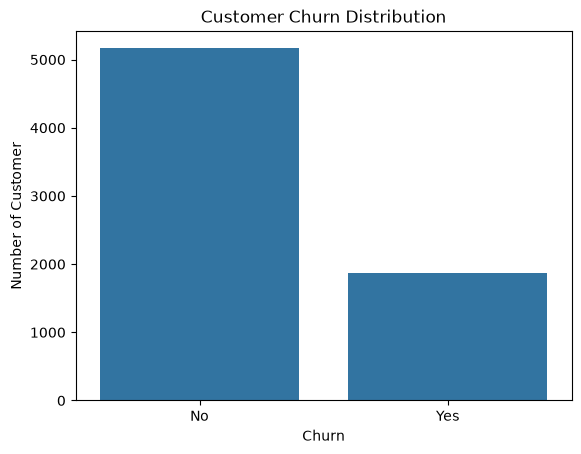

In [159]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customer")
plt.show()

In [160]:
churn_customers = (df["Churn"] == "Yes").sum()
print (churn_customers)

1869


In [161]:
total_customers = len(df)
print (total_customers)

7032


In [162]:
churn_rate = (churn_customers / total_customers) *100
print (churn_rate)

26.578498293515356


In [163]:
print(f"Total Customers: {total_customers}")
print(f"Churned Customers: {churn_customers}")
print(f"Churn Rate: {churn_rate:.2f}%")

Total Customers: 7032
Churned Customers: 1869
Churn Rate: 26.58%


In [164]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1685
One year          1472
Name: count, dtype: int64

In [165]:
pd.crosstab(df["Contract"], df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1306,166
Two year,1637,48


In [166]:
conract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize = "index") * 100
print (conract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


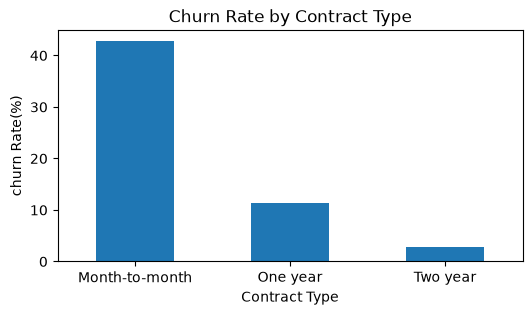

In [167]:
conract_churn["Yes"].sort_values(ascending = False).plot(
    kind = "bar",
    figsize=(6,3)
)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("churn Rate(%)")
plt.xticks(rotation=0)
plt.show()

In [168]:
df["tenure"].describe()

count    7032.000000
mean       32.421786
std        24.545260
min         1.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [169]:
bins = [0, 12, 24, 48, 72]
labels = ["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [170]:
tenure_churn = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100
print(tenure_churn)

Churn                No        Yes
TenureGroup                       
0-12 Months   52.321839  47.678161
13-24 Months  71.289062  28.710938
25-48 Months  79.611041  20.388959
49-72 Months  90.486824   9.513176


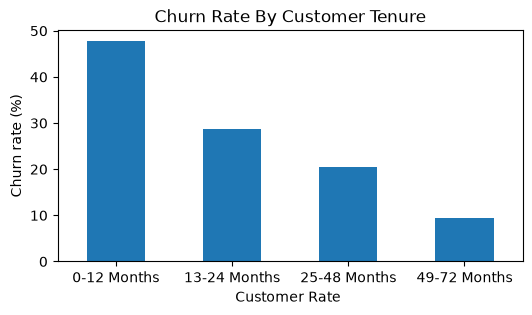

In [171]:
tenure_churn["Yes"].plot(
    kind="bar",
    figsize=(6,3)
)

plt.title("Churn Rate By Customer Tenure")
plt.xlabel("Customer Rate ")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

In [172]:
df["MonthlyCharges"].describe()

count    7032.000000
mean       64.798208
std        30.085974
min        18.250000
25%        35.587500
50%        70.350000
75%        89.862500
max       118.750000
Name: MonthlyCharges, dtype: float64

In [173]:
bins = [0, 30, 60, 90, 120]
labels = ["$0-30", "$31-60", "$61-90", "$91-120"]

df["MonthlyChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins = bins,
    labels=labels,
    include_lowest = True
)

    

In [174]:
monthly_charge_churn = pd.crosstab(
    df["MonthlyChargeGroup"],
    df["Churn"],
    normalize="index"
) *100
print (monthly_charge_churn)


Churn                      No        Yes
MonthlyChargeGroup                      
$0-30               90.163934   9.836066
$31-60              74.030087  25.969913
$61-90              66.051196  33.948804
$91-120             67.222542  32.777458


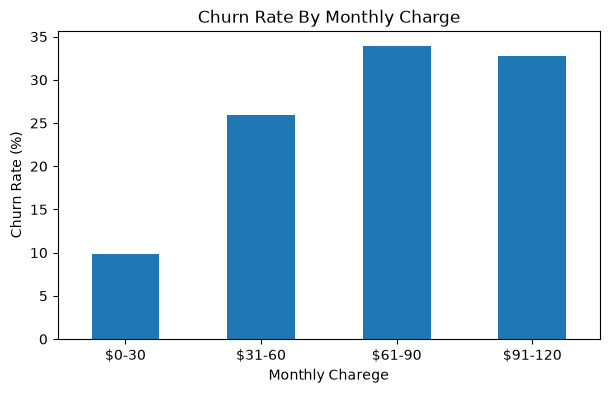

In [175]:
monthly_charge_churn["Yes"] .plot (
    kind = "bar",
    figsize = (7,4)
)
plt.title("Churn Rate By Monthly Charge")
plt.xlabel("Monthly Charege")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [176]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

In [177]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"]
)
print (internet_churn)

Churn              No   Yes
InternetService            
DSL              1957   459
Fiber optic      1799  1297
No               1407   113


In [178]:
internet_churn_rate = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize = "index"
) * 100
print (internet_churn_rate)

Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


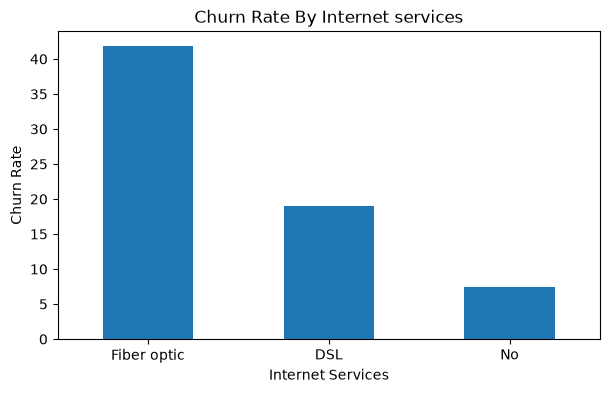

In [179]:
internet_churn_rate["Yes"].sort_values(ascending = False).plot(
    kind ="bar",
    figsize= (7,4)

)
plt.title("Churn Rate By Internet services")
plt.xlabel("Internet Services")
plt.ylabel("Churn Rate")
plt.xticks(rotation=0)
plt.show()
    

In [180]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1604
Bank transfer (automatic)    1542
Credit card (automatic)      1521
Name: count, dtype: int64

In [181]:
payment_churn = pd.crosstab(
    df["PaymentMethod"], 
    df["Churn"],
    normalize= "index"
) * 100
print (payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.268482  16.731518
Credit card (automatic)    84.746877  15.253123
Electronic check           54.714588  45.285412
Mailed check               80.798005  19.201995


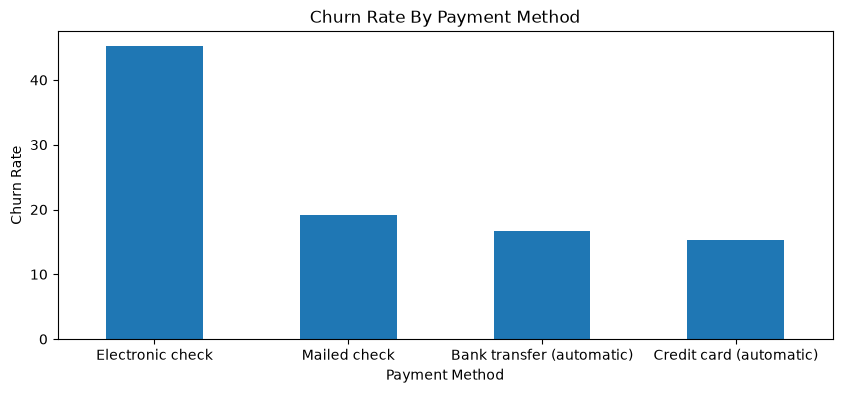

In [182]:
payment_churn ["Yes"].sort_values(ascending = False).plot(
    kind ="bar",
    figsize= (10,4)

)
plt.title("Churn Rate By Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate")
plt.xticks(rotation = 0)
plt.show()

In [183]:
Tech_support_churn = pd.crosstab(
    df["TechSupport"], 
    df["Churn"],
    normalize= "index"
) * 100
print (Tech_support_churn)

Churn                       No        Yes
TechSupport                              
No                   58.352535  41.647465
No internet service  92.565789   7.434211
Yes                  84.803922  15.196078


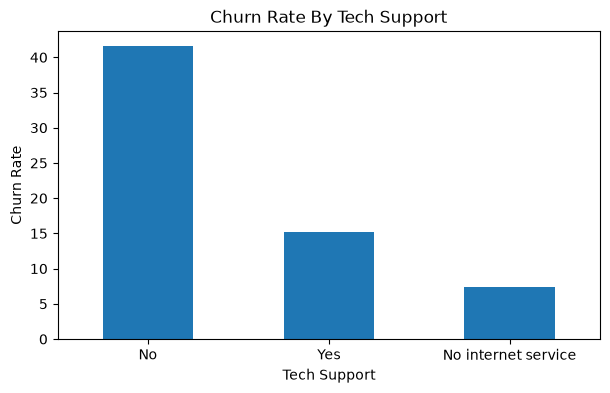

In [184]:
Tech_support_churn ["Yes"].sort_values(ascending = False).plot(
    kind ="bar",
    figsize= (7,4)

)
plt.title("Churn Rate By Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate")
plt.xticks(rotation = 0)
plt.show()

In [185]:
Security_churn = pd.crosstab(
    df["OnlineSecurity"], 
    df["Churn"],
    normalize= "index"
) * 100
print (Security_churn)

Churn                       No        Yes
OnlineSecurity                           
No                   58.221333  41.778667
No internet service  92.565789   7.434211
Yes                  85.359801  14.640199


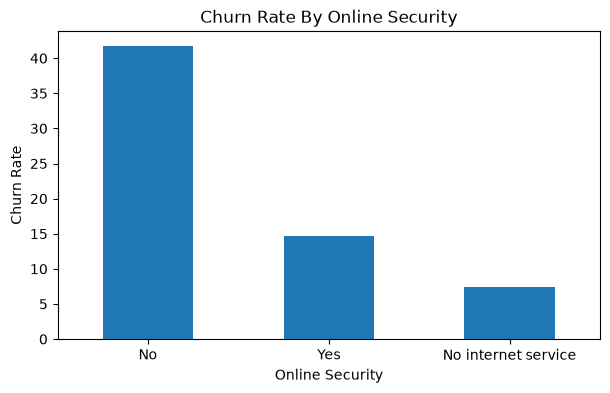

In [186]:
Security_churn ["Yes"].sort_values(ascending = False).plot(
    kind ="bar",
    figsize= (7,4)

)
plt.title("Churn Rate By Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate")
plt.xticks(rotation = 0)
plt.show()

In [187]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

senior_churn

Churn,No,Yes
SeniorCitizen,,
0,76.349745,23.650255
1,58.318739,41.681261


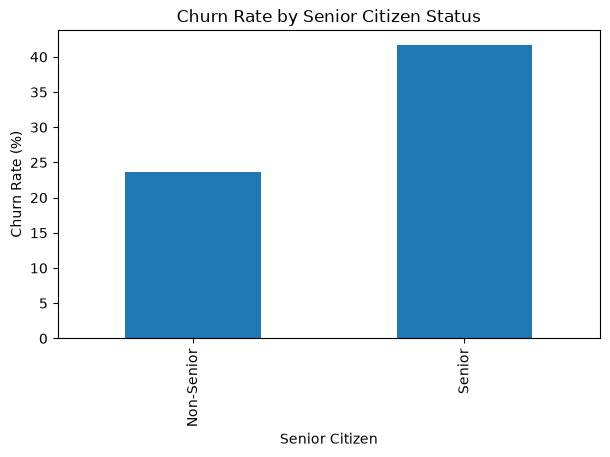

In [188]:
senior_churn["Yes"].plot(
    kind="bar",
    figsize=(7,4)
)

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")
plt.xticks([0, 1], ["Non-Senior", "Senior"])
plt.show()

In [189]:
contract_internet_churn = pd.crosstab(
    [df["Contract"], df["InternetService"]],
    df["Churn"],
    normalize = "index"
)*100
print(contract_internet_churn)

Churn                                  No        Yes
Contract       InternetService                      
Month-to-month DSL              67.784137  32.215863
               Fiber optic      45.394737  54.605263
               No               81.106870  18.893130
One year       DSL              90.701754   9.298246
               Fiber optic      80.705009  19.294991
               No               97.520661   2.479339
Two year       DSL              98.073836   1.926164
               Fiber optic      92.773893   7.226107
               No               99.210111   0.789889


In [190]:
tenure_contract_churn = pd.crosstab(
    [df["TenureGroup"], df["Contract"]],
    df["Churn"],
    normalize="index"
) * 100

tenure_contract_churn

Churn                                No        Yes
TenureGroup  Contract                             
0-12 Months  Month-to-month   48.645938  51.354062
             One year         89.430894  10.569106
             Two year        100.000000   0.000000
13-24 Months Month-to-month   62.279512  37.720488
             One year         91.878173   8.121827
             Two year        100.000000   0.000000
25-48 Months Month-to-month   67.082294  32.917706
             One year         89.382239  10.617761
             Two year         97.810219   2.189781
49-72 Months Month-to-month   73.976608  26.023392
             One year         87.066246  12.933754
             Two year         96.674584   3.325416

In [191]:
tenure_contract_churn["Yes"].sort_values(ascending = False)

TenureGroup   Contract      
0-12 Months   Month-to-month    51.354062
13-24 Months  Month-to-month    37.720488
25-48 Months  Month-to-month    32.917706
49-72 Months  Month-to-month    26.023392
              One year          12.933754
25-48 Months  One year          10.617761
0-12 Months   One year          10.569106
13-24 Months  One year           8.121827
49-72 Months  Two year           3.325416
25-48 Months  Two year           2.189781
0-12 Months   Two year           0.000000
13-24 Months  Two year           0.000000
Name: Yes, dtype: float64

In [192]:
monthly_contract_churn = pd.crosstab(
    [df["Contract"], df["MonthlyChargeGroup"]],
    df["Churn"],
    normalize="index"
) * 100

print(monthly_contract_churn)

Churn                                     No        Yes
Contract       MonthlyChargeGroup                      
Month-to-month $0-30               77.102804  22.897196
               $31-60              64.277321  35.722679
               $61-90              50.360183  49.639817
               $91-120             47.836257  52.163743
One year       $0-30               97.304582   2.695418
               $31-60              92.430279   7.569721
               $61-90              89.108911  10.891089
               $91-120             79.147982  20.852018
Two year       $0-30               99.211356   0.788644
               $31-60              96.894410   3.105590
               $61-90              98.451327   1.548673
               $91-120             92.922374   7.077626


In [193]:
monthly_contract_churn["Yes"].sort_values(ascending = False)

Contract        MonthlyChargeGroup
Month-to-month  $91-120               52.163743
                $61-90                49.639817
                $31-60                35.722679
                $0-30                 22.897196
One year        $91-120               20.852018
                $61-90                10.891089
                $31-60                 7.569721
Two year        $91-120                7.077626
                $31-60                 3.105590
One year        $0-30                  2.695418
Two year        $61-90                 1.548673
                $0-30                  0.788644
Name: Yes, dtype: float64

In [194]:
factor_churn = {
    "Contract":conract_churn["Yes"].max(),
    "Internet Service":internet_churn_rate["Yes"].max(),
    "Payment Method":payment_churn ["Yes"].max(),
    "Tech Support": Tech_support_churn ["Yes"].max(),
    "Online Security":Security_churn ["Yes"].max(),
    "Senior Citizen": senior_churn["Yes"].max()
}
print(factor_churn)

{'Contract': np.float64(42.70967741935484), 'Internet Service': np.float64(41.89276485788114), 'Payment Method': np.float64(45.28541226215645), 'Tech Support': np.float64(41.647465437788014), 'Online Security': np.float64(41.77866742922505), 'Senior Citizen': np.float64(41.68126094570928)}


In [195]:
pd.Series(factor_churn).sort_values(ascending = False)

Payment Method      45.285412
Contract            42.709677
Internet Service    41.892765
Online Security     41.778667
Senior Citizen      41.681261
Tech Support        41.647465
dtype: float64

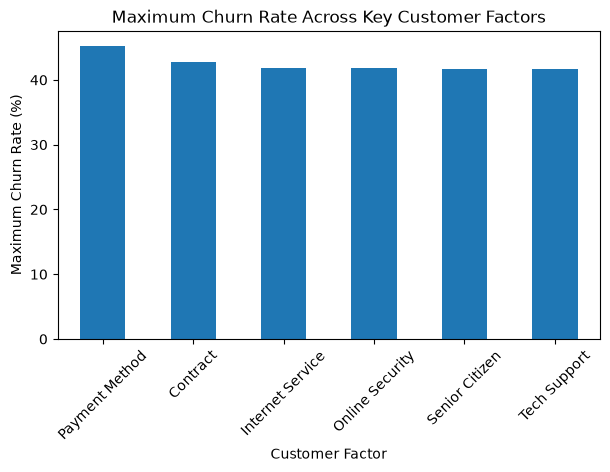

In [197]:
factor_churn_series = pd.Series(factor_churn).sort_values(ascending=False)
factor_churn_series.plot(
    kind="bar",
    figsize=(7,4)
)
plt.title("Maximum Churn Rate Across Key Customer Factors")
plt.xlabel("Customer Factor")
plt.ylabel("Maximum Churn Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [198]:
df["TotalCharges"].isnull().sum()

np.int64(0)

In [199]:
df.to_csv(
    "../data/CustomerChurn_Cleaned.csv",
    index=False
)